## the inevitable rectangles

at least this is easier than the radar towers

In [1]:
from util import file_to_list

In [2]:
floor = file_to_list('./data/day09_test.txt')

In [3]:
def find_red_tiles(floor):
    red_tiles = []
    for row in floor:
        i, j = [int(x) for x in row.split(',')]
        red_tiles.append([i, j])
    return red_tiles

In [4]:
def area(x1, y1, x2, y2):
    x = abs(x1-x2) + 1
    y = abs(y1-y2) + 1
    return x * y

In [5]:
assert area(2, 5, 9, 7) == 24
assert area(7, 1, 11, 7) == 35
assert area(7, 3, 2, 3) == 6

largest rectangle: find all hashtags, try out all combinations

In [6]:
def biggest_red_rectangle(floor):
    red_tiles = find_red_tiles(floor)
    biggest = 0
    for i, r1 in enumerate(red_tiles):
        for r2 in red_tiles[i+1:]:
            current = area(r1[0], r1[1], r2[0], r2[1])
            if current > biggest:
                biggest = current
    return biggest

In [7]:
find_red_tiles(floor)

[[7, 1], [11, 1], [11, 7], [9, 7], [9, 5], [2, 5], [2, 3], [7, 3]]

In [8]:
floor = file_to_list('./data/day09_test.txt')
biggest_red_rectangle(floor)

50

In [9]:
floor = file_to_list('./data/day09.txt')
biggest_red_rectangle(floor)

4748985168

### part 2 

consecutive red tiles are connected by green tiles, all tiles enclosed by the perimeter thus formed are also green. If we only allow red corners and green filling, which rectangles are now allowed?

if a rectangle is completely green, then that means that I can follow the red tiles from r1 to r2 without at any time being inside the rectangle.

In [ ]:
def circumnavigate(r1, r2, red_tiles):
    # find what the corners of this rectangle are
    x = min(r1[0], r2[0])
    y_min = min(r1[1], r2[1])
    y_max = max(r1[1], r2[1])
    

In [ ]:
def upper_left(r1, r2, red_tiles):
    # find what the corners of this rectangle are
    x = min(r1[0], r2[0])
    y = min(r1[1], r2[1])
    for tile in red_tiles:
        if tile[0] <= x and tile[1] <= y:
            return True
    return False

def upper_right(r1, r2, red_tiles):
    # find what the corners of this rectangle are
    x = min(r1[0], r2[0])
    y = max(r1[1], r2[1])
    for tile in red_tiles:
        if tile[0] <= x and tile[1] >= y:
            return True
    return False

def lower_left(r1, r2, red_tiles):
    # find what the corners of this rectangle are
    x = max(r1[0], r2[0])
    y = min(r1[1], r2[1])
    for tile in red_tiles:
        if tile[0] >= x and tile[1] <= y:
            return True
    return False

def lower_right(r1, r2, red_tiles):
    # find what the corners of this rectangle are
    x = max(r1[0], r2[0])
    y = max(r1[1], r2[1])
    for tile in red_tiles:
        if tile[0] >= x and tile[1] >= y:
            return True
    return False

def is_not_green(r1, r2, red_tiles):
    if upper_left(r1, r2, red_tiles):
        if upper_right(r1, r2, red_tiles):
            if lower_left(r1, r2, red_tiles):
                if lower_right(r1, r2, red_tiles):
                    return False
    return True

def is_inside(r1, r2, tile):
    x_min = min(r1[0], r2[0])
    x_max = max(r1[0], r2[0])
    y_min = min(r1[1], r2[1])
    y_max = max(r1[1], r2[1])

    return (x_min < tile[0] < x_max) & (y_min < tile[1] < y_max)

In [ ]:


def biggest_green_rectangle(floor):
    red_tiles = find_red_tiles(floor)
    biggest = 0
    coords = []
    for i, r1 in enumerate(red_tiles):
        for r2 in red_tiles[i+1:]:
            current = area(r1[0], r1[1], r2[0], r2[1])
            if is_not_green(r1, r2, red_tiles) or red_inside(r1, r2, red_tiles):
                continue
            if current > biggest:
                biggest = current
                coords = [r1, r2]
    return biggest, coords

In [47]:
floor = file_to_list('./data/day09_test.txt')
assert biggest_green_rectangle(floor)[0] == 24

1288306560 too low
4618517036 too high

In [ ]:
floor = file_to_list('./data/day09.txt')
area, rect = biggest_green_rectangle(floor)
area

(4618517036, [[16587, 84736], [83238, 15444]])

In [16]:
import matplotlib.pyplot as plt
import numpy as np

In [22]:
floor_num = []
for line in floor:
    x, y = line.split(',')
    floor_num.append([int(x), int(y)])

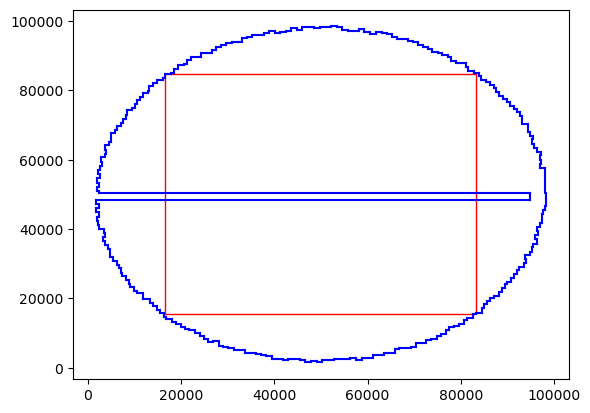

In [ ]:
fig, ax = plt.subplots()
for i, point in enumerate(floor_num[:-1]):
    x1, y1 = point
    x2, y2 = floor_num[i+1]
    ax.plot([x1, x2], [y1, y2], 'b-')

r1, r2 = rect
xy = [min(r1[0], r1[0]), min(r1[1], r2[1])]
width = np.abs(r1[0] - r2[0])
height = np.abs(r1[1] - r2[1])

ax.add_patch(plt.Rectangle(xy, width, height, ls="-", ec="r", fc="none",))